# Advanced Natural Language Processing (968G5): Practical Assignment (Max 5000 words) - Propaganda Detection

## 1. Setup

### 1.1. Load Libraries

In [1]:
from collections import Counter
from datasets import Dataset
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.naive_bayes import MultinomialNB
from torch.optim import AdamW
from torch.utils.data import DataLoader
from torchcrf import CRF
from tqdm import tqdm
from transformers import AutoModel
from transformers import AutoModelForSequenceClassification, AutoModelForTokenClassification, AutoTokenizer, DataCollatorWithPadding, DataCollatorForTokenClassification
import csv
import matplotlib.pyplot as plt
import nltk
import numpy as np
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8" # for reproducibility
os.environ["CUDA_LAUNCH_BLOCKING"] = "1"
import pandas as pd
import pickle
import random
import re
import scipy as sp
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F

### 1.2. Initialise Settings

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
seed = 123

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True)

set_seed(seed)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

g = torch.Generator()
g.manual_seed(seed)

### 1.3. Create Folders

In [3]:
folders = ["data", "figures", "metrics", "tables"]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

### 1.4. Read in Data

In [4]:
train_df = pd.read_csv(
    "data/propaganda_train.tsv",
    sep="\t",
    engine="python",
    quoting=csv.QUOTE_NONE,
    on_bad_lines="warn"
)

test_df = pd.read_csv(
    "data/propaganda_val.tsv",
    sep="\t",
    engine="python",
    quoting=csv.QUOTE_NONE,
    on_bad_lines="warn"
)

# Note: Some of the rows in the .tsv files 
# had malformed quote marks which prevented 
# pandas from reading in rows correctly. 
# quoting=csv.QUOTE_NONE just ensures read_csv
# escapes quote marks correctly.

### 1.5. Data Preprocessing

#### 1.5.1. Create Cleaned Text

In [5]:
train_df["cleaned_text"] = (
    train_df["tagged_in_context"]
    .str.replace(r"<BOS>|<EOS>", "", regex=True)
    .str.replace(r" ([^\w\s])", r"\1", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

test_df["cleaned_text"] = (
    test_df["tagged_in_context"]
    .str.replace(r"<BOS>|<EOS>", "", regex=True)
    .str.replace(r" ([^\w\s])", r"\1", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

In [6]:
train_df["cleaned_text_len"] = train_df["cleaned_text"].apply(lambda x: len(x.split()))
test_df["cleaned_text_len"] = test_df["cleaned_text"].apply(lambda x: len(x.split()))

## 2. EDA

### 2.1. Class Distribution

In [7]:
multiclass_proportion_train_df = train_df["label"].value_counts(normalize=True).reset_index()
multiclass_proportion_test_df = test_df["label"].value_counts(normalize=True).reset_index()

multiclass_proportion_train_df["split"] = "train"
multiclass_proportion_test_df["split"] = "test"

combined_multiclass_proportion_df = pd.concat([
    multiclass_proportion_train_df, 
    multiclass_proportion_test_df
])

In [8]:
multiclass_order = sorted(combined_multiclass_proportion_df["label"].unique())
palette = {k: v for k, v in zip(multiclass_order, sns.color_palette()[:len(multiclass_order)])}

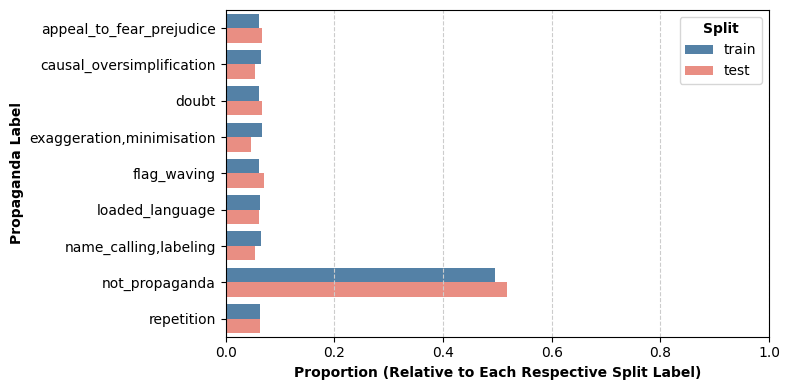

In [9]:
plt.figure(figsize=(8, 4))

sns.barplot(
    data=combined_multiclass_proportion_df,
    x="proportion",
    y="label",
    hue="split",
    order=multiclass_order,
    palette={"train": "steelblue", "test": "salmon"}
)

plt.xlabel("Proportion (Relative to Each Respective Split Label)", fontsize=10, fontweight="bold")
plt.ylabel("Propaganda Label", fontsize=10, fontweight="bold")

plt.xlim(0, 1)

plt.grid(axis="x", color="0.8", linestyle="--")

plt.legend(
    title="Split",
    title_fontproperties={
        "size": 10, 
        "weight": "bold"
    }
)

plt.tight_layout()
plt.savefig(
    "figures/class_distribution_comparison_plot.png",
    dpi=600
)
plt.show()

### 2.2 Snippet and Sentential Context

In [10]:
def extract_span_and_context(text):
    span_match = re.search(r"<BOS>(.*?)<EOS>", text)
    span = span_match.group(1).strip() if span_match else ""
    context = re.sub(r"<BOS>.*?<EOS>", "", text)
    context = re.sub(r"\s+", " ", context).strip()
    if not re.search(r"[A-Za-z0-9]", context):
        context = ""
    return span, context

train_df[["snippet", "context"]] = train_df["tagged_in_context"].apply(
    lambda x: pd.Series(extract_span_and_context(x))
)

test_df[["snippet", "context"]] = test_df["tagged_in_context"].apply(
    lambda x: pd.Series(extract_span_and_context(x))
)

In [11]:
full_dataset_df = pd.concat([train_df, test_df])

propaganda_only_df = full_dataset_df[full_dataset_df["label"] != "not_propaganda"]

In [12]:
nltk.download('stopwords', quiet=True)
stop_words = set(stopwords.words('english'))

labels = propaganda_only_df["label"].unique()

def get_top_ngrams(text, n=10):
    words = re.findall(r'\b\w+\b', text.lower())
    
    unigrams = [w for w in words if w not in stop_words]

    bigrams = [
        f"{w1} {w2}"
        for w1, w2 in zip(words, words[1:])
        if not (w1 in stop_words and w2 in stop_words)
    ]

    all_terms = unigrams + bigrams

    return [term for term, _ in Counter(all_terms).most_common(n)]

most_common_words_data = {
    "snippet": {},
    "context": {}
}

for label in labels:
    subset = propaganda_only_df[propaganda_only_df["label"] == label]

    snippet_text = " ".join(subset["snippet"].dropna().astype(str))
    context_text = " ".join(subset["context"].dropna().astype(str))

    most_common_words_data["snippet"][label] = ", ".join(
        get_top_ngrams(snippet_text)
    )

    most_common_words_data["context"][label] = ", ".join(
        get_top_ngrams(context_text)
    )

most_common_words_df = pd.DataFrame(most_common_words_data).reset_index(names="label").sort_values("label")
most_common_words_df.columns = [c.title() for c in most_common_words_df.columns]

most_common_words_df.to_csv("tables/most_common_words_df.csv", index=False)

most_common_words_df

,Label,Snippet,Context
4,appeal_to_fear_prejudice,"church, one, would, the church, people, u, u s...","said, many, letter, us, trump, plague, could, ..."
6,causal_oversimplification,"one, god, cia, church, the cia, the church, tr...","said, one, would, security, like, words, natio..."
2,doubt,"guardian, the guardian, people, even, evidence...","said, church, question, also, cannot, kavanaug..."
7,"exaggeration,minimisation","world, one, history, ever, thing, the world, c...","one, trump, said, president, people, one of, c..."
0,flag_waving,"american, people, america, american people, th...","trump, said, continue, president, public, put,..."
1,loaded_language,"church, people, life, smear, whoa, scandal, po...","trump, church, said, would, also, new, many, t..."
3,"name_calling,labeling","trump, leftist, left, america, disgrace, anti,...","trump, one, would, church, news, assange, cath..."
5,repetition,"aliens, people, autonomy, trump, illegal, ille...","one, said, parents, trump, many, obama, school..."


## 3. Modelling

In [13]:
with open("metrics/train_size.pkl", "wb") as f:
    pickle.dump(train_df.shape[0], f)

with open("metrics/test_size.pkl", "wb") as f:
    pickle.dump(test_df.shape[0], f)

### 3.1. Task 1: Propaganda Snippet Multimodal Classification

In [14]:
propaganda_only_train_df = train_df[train_df["label"] != "not_propaganda"][["label", "tagged_in_context", "snippet", "context"]].reset_index(drop=True)
propaganda_only_test_df = test_df[test_df["label"] != "not_propaganda"][["label", "tagged_in_context", "snippet", "context"]].reset_index(drop=True)

#### 3.1.1. Method 1: Multimodal Naive Bayes

In [15]:
snippet_vectoriser = TfidfVectorizer(ngram_range=(1, 2), min_df=2, token_pattern=r"\w+|[!?]")
context_vectoriser = TfidfVectorizer(ngram_range=(1, 2), min_df=2, token_pattern=r"\w+|[!?]")

X_train_snippet_vectors = snippet_vectoriser.fit_transform(propaganda_only_train_df["snippet"])
X_train_context_vectors = context_vectoriser.fit_transform(propaganda_only_train_df["context"])

X_test_snippet_vectors = snippet_vectoriser.transform(propaganda_only_test_df["snippet"])
X_test_context_vectors = context_vectoriser.transform(propaganda_only_test_df["context"])

X_train_concatenated_vectors = sp.sparse.hstack([X_train_snippet_vectors, X_train_context_vectors])
X_test_concatenated_vectors = sp.sparse.hstack([X_test_snippet_vectors, X_test_context_vectors])

In [16]:
classifier=MultinomialNB()
classifier.fit(X_train_concatenated_vectors, propaganda_only_train_df["label"])
y_pred = classifier.predict(X_test_concatenated_vectors)
y_true = propaganda_only_test_df["label"]

In [17]:
with open("metrics/multimodalNB_accuracy.pkl", "wb") as f:
    pickle.dump(accuracy_score(y_true, y_pred), f)

print(f"{accuracy_score(y_true, y_pred):.3f}")

0.466


In [18]:
multinomialNB_classification_report = classification_report(
    y_true, 
    y_pred, 
    output_dict=True
)

In [19]:
multinomialNB_classification_report_df = (
    pd.DataFrame(multinomialNB_classification_report)
    .transpose()
    .drop(columns="support")
    .reset_index(names="label")
)

multinomialNB_classification_report_df["label"] = multinomialNB_classification_report_df["label"].apply(
    lambda x: x.replace("_", " ").title()
)

multinomialNB_classification_report_df.columns = [c.title() for c in multinomialNB_classification_report_df.columns]
multinomialNB_classification_report_df

,Label,Precision,Recall,F1-Score
0,Appeal To Fear Prejudice,0.432432,0.372093,0.400000
1,Causal Oversimplification,0.360656,0.628571,0.458333
2,Doubt,0.605263,0.534884,0.567901
3,"Exaggeration,Minimisation",0.342105,0.433333,0.382353
4,Flag Waving,0.595745,0.622222,0.608696
5,Loaded Language,0.444444,0.205128,0.280702
6,"Name Calling,Labeling",0.437500,0.617647,0.512195
7,Repetition,0.590909,0.325000,0.419355
8,Accuracy,0.466019,0.466019,0.466019
9,Macro Avg,0.476132,0.467360,0.453692


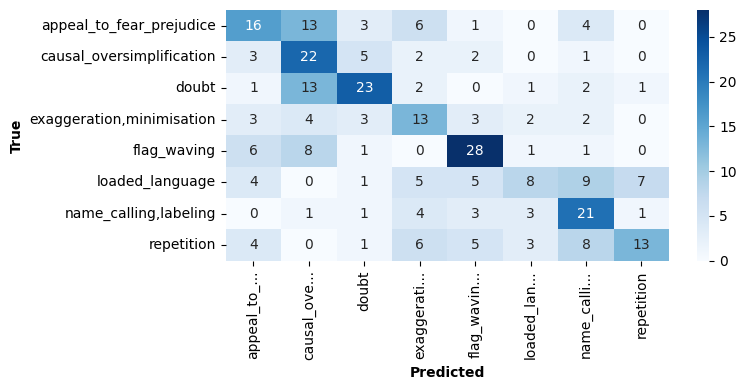

In [20]:
conf_matrix = confusion_matrix(
    y_true, 
    y_pred, 
    labels=classifier.classes_
)

truncated_class_labels = [str(c)[:10] + "..." if len(c) > 10 else str(c) for c in classifier.classes_]

plt.figure(figsize=(8,4))

sns.heatmap(
    conf_matrix, 
    annot=True, 
    xticklabels=truncated_class_labels, 
    yticklabels=classifier.classes_, 
    cmap="Blues"
)

plt.xlabel("Predicted", fontsize=10, fontweight="bold")
plt.ylabel("True", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.savefig("figures/mutlinomialNB_confusion_matrix_plot.png", dpi=600)
plt.show()

In [21]:
snippet_features = snippet_vectoriser.get_feature_names_out()
context_features = context_vectoriser.get_feature_names_out()

feature_names = np.concatenate([snippet_features, context_features])

def most_discriminative_features_per_class(classifier, feature_names, class_labels, top_n=10):
    
    log_probs = classifier.feature_log_prob_
    n_classes = log_probs.shape[0]
    
    rows = []
    
    for i in range(n_classes):

        others = np.mean(
            np.delete(log_probs, i, axis=0),
            axis=0
        )
        
        scores = log_probs[i] - others
        
        top_idx = np.argsort(scores)[::-1][:top_n]
        
        top_words = [feature_names[j] for j in top_idx]
        
        rows.append({
            "Label": class_labels[i],
            "Most Discriminative Features": ", ".join(top_words)
        })
    
    return pd.DataFrame(rows)

most_discriminative_features_per_class_df = most_discriminative_features_per_class(
    classifier=classifier,
    feature_names=feature_names,
    class_labels=classifier.classes_,
    top_n=10
)

most_discriminative_features_per_class_df.to_csv("tables/most_discriminative_features_per_class_df.csv", index=False)

most_discriminative_features_per_class_df

,Label,Most Discriminative Features
0,appeal_to_fear_prejudice,"if, we, will, threatened, face, fear, must, be..."
1,causal_oversimplification,"because, they, she, clearly, it, that, cia, th..."
2,doubt,"?, why, but, t, guardian, ?, evidence, he, wha..."
3,"exaggeration,minimisation","the most, most, history, thing, ever, the worl..."
4,flag_waving,"our, american, american people, the american, ..."
5,loaded_language,"violently, damn, wrath, outright, agenda, viol..."
6,"name_calling,labeling","leftist, infidels, unbelievers, liar, partisan..."
7,repetition,"autonomy, aliens, autonomous, annihilated, ill..."


#### 3.1.2. Method 2: BERT

##### 3.1.2.1. BERT Hyperparameters

In [22]:
batch_size = 8
learning_rate = 2e-5
max_token_length = 512
num_epochs = 3
pretrained_bert_model = "distilbert-base-uncased"
validation_set_size = 0.2
weight_decay = 0.01

task_1_approach_b_hyperparameters = {
    "batch_size": batch_size,
    "learning_rate": learning_rate,
    "max_token_length": max_token_length,
    "num_epochs": num_epochs,
    "pretrained_bert_model": pretrained_bert_model,
    "validation_test_size": validation_set_size,
    "weight_decay": weight_decay
}

task_1_approach_b_hyperparameters_df = pd.DataFrame(
    list(task_1_approach_b_hyperparameters.items()),
    columns=["Parameter", "Value"]
)

task_1_approach_b_hyperparameters_df.to_csv("tables/task_1_approach_b_hyperparameters_df.csv", index=False)

In [23]:
train_dataset = Dataset.from_pandas(propaganda_only_train_df[["label", "tagged_in_context"]])
test_dataset = Dataset.from_pandas(propaganda_only_test_df[["label", "tagged_in_context"]])

In [24]:
set_seed(seed)

unique_labels = sorted(propaganda_only_train_df["label"].unique())
label2id = {label: i for i, label in enumerate(unique_labels)}
id2label = {i: label for i, label in enumerate(unique_labels)}

tokeniser = AutoTokenizer.from_pretrained(pretrained_bert_model)

special_tokens = {"additional_special_tokens": ["<BOS>", "<EOS>"]}
tokeniser.add_special_tokens(special_tokens)

model = AutoModelForSequenceClassification.from_pretrained(
    pretrained_bert_model, 
    num_labels=len(unique_labels), 
    id2label=id2label, 
    label2id=label2id
)

model.resize_token_embeddings(len(tokeniser))

model = model.to(device)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 3168.33it/s]
DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nl

In [25]:
def tokenize(example):
    return tokeniser(
        example["tagged_in_context"],
        truncation=True,
        max_length=max_token_length
    )

def add_labels(example):
    example["labels"] = label2id[example["label"]]
    return example

train_dataset = train_dataset.map(tokenize, batched=True)
train_dataset = train_dataset.map(add_labels)

test_dataset = test_dataset.map(tokenize, batched=True)
test_dataset = test_dataset.map(add_labels)

train_dataset = train_dataset.remove_columns(["label"])
test_dataset = test_dataset.remove_columns(["label"])

train_dataset.set_format(
    type="torch",
    columns=["input_ids", "attention_mask", "labels"]
)

test_dataset.set_format(
    type="torch",
    columns=["input_ids", "attention_mask", "labels"]
)

data_collator = DataCollatorWithPadding(tokenizer=tokeniser)

Map: 100%|██████████| 309/309 [00:00<00:00, 9908.26 examples/s]


In [26]:
train_validation_dataset = train_dataset.train_test_split(
    test_size=validation_set_size, 
    seed=seed
)

In [27]:
train_sampler = torch.utils.data.RandomSampler(
    train_validation_dataset["train"]
)

val_sampler = torch.utils.data.SequentialSampler(
    train_validation_dataset["test"]
)

test_sampler = torch.utils.data.SequentialSampler(
    test_dataset
)

train_loader = DataLoader(
    train_validation_dataset["train"],
    batch_size=batch_size,
    collate_fn=data_collator,
    sampler=train_sampler,
    worker_init_fn=seed_worker,
    generator=g, 
)

val_loader = DataLoader(
    train_validation_dataset["test"],
    batch_size=batch_size,
    collate_fn=data_collator,
    sampler=val_sampler,
    worker_init_fn=seed_worker,
    generator=g, 
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    collate_fn=data_collator,
    sampler=test_sampler,
    worker_init_fn=seed_worker,
    generator=g, 
)

In [28]:
set_seed(seed)

losses_dict = {
    "epoch": [],
    "train": [],
    "validation": []
}

optimiser = AdamW(
    params=model.parameters(), 
    lr=learning_rate,
    weight_decay=weight_decay
)

for epoch in range(num_epochs):
    model.train()
    total_loss = 0

    for batch in tqdm(train_loader, desc=f"Processing Batches from Epoch {epoch+1}"):
        batch = {k: v.to(device) for k, v in batch.items()}

        outputs = model(**batch)
        loss = outputs.loss

        optimiser.zero_grad()
        loss.backward()
        optimiser.step()

        total_loss += loss.item()

    avg_train_loss = total_loss / len(train_loader)

    model.eval()
    val_preds = []
    val_true = []
    val_loss = 0

    with torch.no_grad():
        for batch in val_loader:
            batch = {k: v.to(device) for k, v in batch.items()}

            outputs = model(**batch)
            val_loss += outputs.loss.item()

            preds = torch.argmax(outputs.logits, dim=1)

            val_preds.extend(preds.cpu().numpy())
            val_true.extend(batch["labels"].cpu().numpy())

    avg_val_loss = val_loss / len(val_loader)
    val_acc = accuracy_score(val_true, val_preds)

    losses_dict["epoch"].append(epoch+1)
    losses_dict["train"].append(avg_train_loss)
    losses_dict["validation"].append(avg_val_loss)

    print(f"--- Epoch {epoch+1} Results ---")
    print(f"Train Loss: {avg_train_loss:.4f}")
    print(f"Val Loss: {avg_val_loss:.4f}")
    print(f"Val Accuracy: {val_acc:.4f}\n")

Processing Batches from Epoch 1: 100%|██████████| 129/129 [00:12<00:00, 10.39it/s]


--- Epoch 1 Results ---
Train Loss: 2.0419
Val Loss: 1.9498
Val Accuracy: 0.3205



Processing Batches from Epoch 2: 100%|██████████| 129/129 [00:11<00:00, 11.16it/s]


--- Epoch 2 Results ---
Train Loss: 1.6895
Val Loss: 1.5602
Val Accuracy: 0.4479



Processing Batches from Epoch 3: 100%|██████████| 129/129 [00:11<00:00, 11.13it/s]


--- Epoch 3 Results ---
Train Loss: 1.1002
Val Loss: 1.4289
Val Accuracy: 0.5019



In [29]:
model.eval()

test_preds = []
test_true = []

with torch.no_grad():
    for batch in test_loader:
        batch = {k: v.to(device) for k, v in batch.items()}

        outputs = model(**batch)
        logits = outputs.logits

        preds = torch.argmax(logits, dim=1)

        test_preds.extend(preds.cpu().numpy())
        test_true.extend(batch["labels"].cpu().numpy())

bert_accuracy = accuracy_score(test_true, test_preds)

with open("metrics/bert_accuracy.pkl", "wb") as f:
    pickle.dump(bert_accuracy, f)

print(f"Test Accuracy: {bert_accuracy:.4f}")

Test Accuracy: 0.5307


In [30]:
BERT_classification_report = classification_report(
    test_true, 
    test_preds, 
    output_dict=True
)

In [31]:
BERT_classification_report_label_mapping = {str(k): v for k, v in id2label.items()}

In [32]:
BERT_classification_report_df = (
    pd.DataFrame(BERT_classification_report)
    .drop(columns="accuracy")
    .transpose()
    .drop(columns="support")
    .reset_index(names="label")
)

BERT_classification_report_df["label"] = (
    BERT_classification_report_df["label"]
    .map(BERT_classification_report_label_mapping)
    .fillna(BERT_classification_report_df["label"])
)

BERT_classification_report_df["label"] = BERT_classification_report_df["label"].apply(
    lambda x: x.replace("_", " ").title()
)

BERT_classification_report_df.columns = [c.title() for c in BERT_classification_report_df.columns]

BERT_classification_report_df

,Label,Precision,Recall,F1-Score
0,Appeal To Fear Prejudice,0.520000,0.604651,0.559140
1,Causal Oversimplification,0.431818,0.542857,0.481013
2,Doubt,0.710526,0.627907,0.666667
3,"Exaggeration,Minimisation",0.454545,0.333333,0.384615
4,Flag Waving,0.640000,0.711111,0.673684
5,Loaded Language,0.375000,0.384615,0.379747
6,"Name Calling,Labeling",0.617647,0.617647,0.617647
7,Repetition,0.451613,0.350000,0.394366
8,Macro Avg,0.525144,0.521515,0.519610
9,Weighted Avg,0.531237,0.530744,0.527457


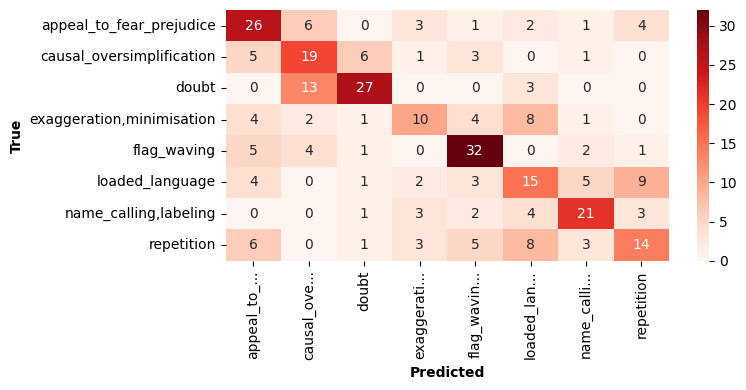

In [33]:
conf_matrix = confusion_matrix(
    test_true, 
    test_preds
)

truncated_class_labels = [str(c)[:10] + "..." if len(c) > 10 else str(c) for c in unique_labels]

plt.figure(figsize=(8,4))

sns.heatmap(
    conf_matrix, 
    annot=True, 
    xticklabels=truncated_class_labels, 
    yticklabels=unique_labels, 
    cmap="Reds"
)

plt.xlabel("Predicted", fontsize=10, fontweight="bold")
plt.ylabel("True", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.savefig("figures/BERT_confusion_matrix_plot.png", dpi=600)
plt.show()

### 3.2 Task 2: Propaganda Span Identification + Multimodal Classification

In [34]:
def span_f1(gold_texts, pred_texts) -> float:

    if not gold_texts:
        return 0.0, 0.0, 0.0

    sum_precision_ratio = 0.0
    total_predicted_spans = 0
    sum_recall_ratio = 0.0
    total_gold_spans = 0

    for gold, pred in zip(gold_texts, pred_texts):
        # Character sets for gold and predicted span
        gold_chars = set(range(len(gold)))  # gold always non-empty here
        if pred:  # non-empty prediction
            pred_chars = set(range(len(pred)))
            overlap = len(gold_chars & pred_chars)
            sum_precision_ratio += overlap / len(pred)
            total_predicted_spans += 1
        else:
            overlap = 0
            # no predicted span, so no contribution to precision

        sum_recall_ratio += overlap / len(gold)
        total_gold_spans += 1

    P = sum_precision_ratio / total_predicted_spans if total_predicted_spans > 0 else 0.0
    R = sum_recall_ratio / total_gold_spans
    F1 = 2 * P * R / (P + R) if (P + R) > 0 else 0.0
    return F1

#### 3.2.1 Approach A: BIO Tagging with DistilBERT

In [35]:
batch_size = 8
learning_rate = 2e-5
max_token_length = 512
num_epochs = 3
pretrained_bert_model = "distilbert-base-uncased"
validation_set_size = 0.2
weight_decay = 0.01

task_2_hyperparameters = {
    "batch_size": batch_size,
    "learning_rate": learning_rate,
    "max_token_length": max_token_length,
    "num_epochs": num_epochs,
    "pretrained_bert_model": pretrained_bert_model,
    "validation_test_size": validation_set_size,
    "weight_decay": weight_decay
}

task_2_hyperparameters_df = pd.DataFrame(
    list(task_2_hyperparameters.items()),
    columns=["Parameter", "Value"]
)

task_2_hyperparameters_df.to_csv("tables/task_2_hyperparameters_df.csv", index=False)

In [36]:
def bio_tag(text, label):
    text = re.sub(r"<EOS>\S+", "<EOS>", text)
    tokens = text.split()
 
    cleaned_tokens = []
    tags = []
 
    # CASE 1: no propaganda → all O
    if label == "not_propaganda":
        for token in tokens:
            if token not in ("<BOS>", "<EOS>"):
                cleaned_tokens.append(token)
                tags.append("O")
        return list(zip(cleaned_tokens, tags))
 
    # CASE 2: propaganda → BIO tagging
    inside = False
    first_inside = False
 
    for token in tokens:
        if token == "<BOS>":
            inside = True
            first_inside = True
            continue
        if token == "<EOS>":
            inside = False
            continue
 
        cleaned_tokens.append(token)
 
        if inside:
            if first_inside:
                tags.append(f"B-{label}")
                first_inside = False
            else:
                tags.append(f"I-{label}")
        else:
            tags.append("O")
 
    return list(zip(cleaned_tokens, tags))
 
train_df["bio_tagged_text"] = train_df.apply(
    lambda row: bio_tag(row["tagged_in_context"], row["label"]),
    axis=1
)
 
test_df["bio_tagged_text"] = test_df.apply(
    lambda row: bio_tag(row["tagged_in_context"], row["label"]),
    axis=1
)

In [37]:
all_tags = set()
 
for bio_list in train_df["bio_tagged_text"]:
    for _, tag in bio_list:
        all_tags.add(tag)
 
unique_tags = sorted(all_tags)
tag2id = {tag: i for i, tag in enumerate(unique_tags)}
id2tag = {i: tag for i, tag in enumerate(unique_tags)}

In [38]:
tokeniser = AutoTokenizer.from_pretrained(pretrained_bert_model)
 
def tokenize_and_align_labels(bio_tagged_text):
    words = [w for w, _ in bio_tagged_text]
    labels = [l for _, l in bio_tagged_text]
 
    tokenized = tokeniser(
        words,
        is_split_into_words=True,
        truncation=True,
        max_length=max_token_length
    )
 
    word_ids = tokenized.word_ids()
    aligned_labels = []
    prev_word_id = None
 
    for word_id in word_ids:
        if word_id is None:
            aligned_labels.append(-100)
        elif word_id != prev_word_id:
            aligned_labels.append(tag2id[labels[word_id]])
        else:
            aligned_labels.append(-100)
        prev_word_id = word_id
 
    tokenized["labels"] = aligned_labels
    return tokenized
 
train_encodings = train_df["bio_tagged_text"].apply(tokenize_and_align_labels).tolist()
test_encodings = test_df["bio_tagged_text"].apply(tokenize_and_align_labels).tolist()

In [39]:
train_size = int((1 - validation_set_size) * len(train_encodings))
train_only_encodings = train_encodings[:train_size]
val_encodings = train_encodings[train_size:]
 
class BIODataset(torch.utils.data.Dataset):
    def __init__(self, encodings):
        self.encodings = encodings
 
    def __getitem__(self, idx):
        return {key: torch.tensor(val) for key, val in self.encodings[idx].items()}
 
    def __len__(self):
        return len(self.encodings)
 
bio_train_dataset = BIODataset(train_only_encodings)
bio_val_dataset   = BIODataset(val_encodings)
bio_test_dataset  = BIODataset(test_encodings)

In [40]:
tag_counts = Counter()
 
for encoding in train_encodings:
    for label in encoding["labels"]:
        if label != -100:
            tag_counts[label] += 1
 
print("Tag counts:")
for tag_id, count in sorted(tag_counts.items()):
    print(f"  {id2tag[tag_id]}: {count}")
 
total = sum(tag_counts.values())
weights = torch.zeros(len(unique_tags))
 
for tag_id, count in tag_counts.items():
    weights[tag_id] = total / (len(unique_tags) * count)
 
weights = weights.to(device)
print(f"\nClass weights: {weights}")
 
loss_fn = nn.CrossEntropyLoss(weight=weights, ignore_index=-100, reduction="mean")

Tag counts:
  B-appeal_to_fear_prejudice: 137
  B-causal_oversimplification: 157
  B-doubt: 137
  B-exaggeration,minimisation: 153
  B-flag_waving: 135
  B-loaded_language: 145
  B-name_calling,labeling: 146
  B-repetition: 134
  I-appeal_to_fear_prejudice: 2171
  I-causal_oversimplification: 3223
  I-doubt: 2724
  I-exaggeration,minimisation: 955
  I-flag_waving: 1216
  I-loaded_language: 348
  I-name_calling,labeling: 490
  I-repetition: 219
  O: 52732

Class weights: tensor([28.0043, 24.4369, 28.0043, 25.0757, 28.4192, 26.4592, 26.2780, 28.6313,
         1.7672,  1.1904,  1.4084,  4.0174,  3.1551, 11.0247,  7.8298, 17.5187,
         0.0728], device='cuda:0')


In [41]:
total_tags = sum(tag_counts.values())

o_count = tag_counts[next(k for k, v in id2tag.items() if v == "O")]

o_percentage = 100 * o_count / total_tags

with open("metrics/o_percentage.pkl", "wb") as f:
    pickle.dump(round(o_percentage, 2), f)

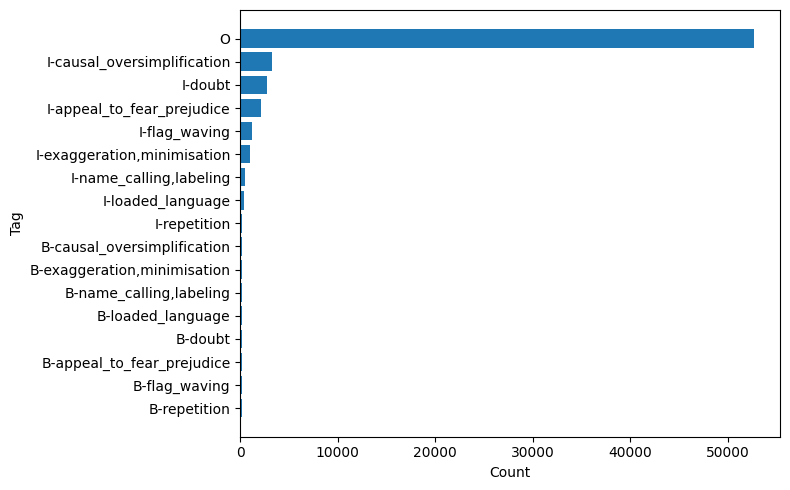

In [42]:
bio_tag_distribution_df = pd.DataFrame(
    [
        {
            "tag": id2tag[tag_id],
            "count": count
        }
        for tag_id, count in sorted(tag_counts.items())
    ]
).sort_values("count", ascending=True)

plt.figure(figsize=(8, 5))
plt.barh(bio_tag_distribution_df["tag"], bio_tag_distribution_df["count"])

plt.xlabel("Count")
plt.ylabel("Tag")
#plt.title("BIO Tag Frequency Distribution")

plt.tight_layout()
plt.savefig("figures/bio_tag_frequency_distribution.png", dpi=600)
plt.show()

In [43]:
bio_train_sampler = torch.utils.data.RandomSampler(bio_train_dataset)
bio_val_sampler   = torch.utils.data.SequentialSampler(bio_val_dataset)
bio_test_sampler  = torch.utils.data.SequentialSampler(bio_test_dataset)
 
data_collator = DataCollatorForTokenClassification(tokenizer=tokeniser)
 
bio_train_loader = DataLoader(
    bio_train_dataset,
    batch_size=batch_size,
    sampler=bio_train_sampler,
    collate_fn=data_collator,
    worker_init_fn=seed_worker,
    generator=g
)
 
bio_val_loader = DataLoader(
    bio_val_dataset,
    batch_size=batch_size,
    sampler=bio_val_sampler,
    collate_fn=data_collator,
    worker_init_fn=seed_worker,
    generator=g
)
 
bio_test_loader = DataLoader(
    bio_test_dataset,
    batch_size=batch_size,
    sampler=bio_test_sampler,
    collate_fn=data_collator,
    worker_init_fn=seed_worker,
    generator=g
)

In [44]:
def extract_spans_with_indices(tokens, tag_ids, id2tag):
    spans = []
    current_tokens, current_label, start_idx = [], None, None
    for i, (token, tag_id) in enumerate(zip(tokens, tag_ids)):
        tag = id2tag[tag_id]
        if tag.startswith("B-"):
            if current_tokens:
                spans.append((" ".join(current_tokens), current_label, list(range(start_idx, i))))
            current_tokens = [token]
            current_label = tag[2:]
            start_idx = i
        elif tag.startswith("I-"):
            label = tag[2:]
            if current_tokens and current_label == label:
                current_tokens.append(token)
        else:
            if current_tokens:
                spans.append((" ".join(current_tokens), current_label, list(range(start_idx, i))))
                current_tokens, current_label, start_idx = [], None, None
    if current_tokens:
        spans.append((" ".join(current_tokens), current_label, list(range(start_idx, len(tokens)))))
    return spans

def select_best_span(bio_tagged_row, pred_tag_ids, probs, id2tag):
    tokens = [w for w, _ in bio_tagged_row]
    spans = extract_spans_with_indices(tokens, pred_tag_ids, id2tag)
    if not spans:
        return "", "not_propaganda"

    log_probs = F.log_softmax(probs, dim=-1)

    best_score = -float("inf")
    best_span = ("", "not_propaganda")
    for span_text, label, indices in spans:
        score = 0.0
        for idx in indices:
            tag_id = pred_tag_ids[idx]
            score += log_probs[idx, tag_id].item()
        max_score = max(log_probs[idx, tag_id].item() for idx in indices)
        if max_score > best_score:
            best_score = max_score
            best_span = (span_text, label)
    return best_span

In [45]:
set_seed(seed)
 
bio_bert_model = AutoModelForTokenClassification.from_pretrained(
    pretrained_bert_model,
    num_labels=len(unique_tags),
    id2label=id2tag,
    label2id=tag2id
)
bio_bert_model = bio_bert_model.to(device)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 3271.71it/s]
DistilBertForTokenClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [46]:
set_seed(seed)
 
bio_bert_losses = {"epoch": [], "train": [], "validation": [], "val f1": []}
 
optimiser = AdamW(
    params=bio_bert_model.parameters(),
    lr=learning_rate,
    weight_decay=weight_decay
)
 
for epoch in range(num_epochs):
    bio_bert_model.train()
    total_loss = 0
 
    for batch in tqdm(bio_train_loader, desc=f"BIO-BERT Epoch {epoch+1}"):
        batch = {k: v.to(device) for k, v in batch.items()}
 
        outputs = bio_bert_model(**batch)
        logits  = outputs.logits
 
        # Use weighted cross-entropy loss (ignore_index=-100 handles padding)
        loss = loss_fn(
            logits.view(-1, len(unique_tags)),
            batch["labels"].view(-1)
        )
 
        optimiser.zero_grad()
        loss.backward()
        optimiser.step()
        total_loss += loss.item()
 
    avg_train_loss = total_loss / len(bio_train_loader)
 
    # Validation
    bio_bert_model.eval()
    val_loss = 0
    val_preds_flat  = []
    val_labels_flat = []
 
    with torch.no_grad():
        for batch in bio_val_loader:
            batch = {k: v.to(device) for k, v in batch.items()}
 
            outputs = bio_bert_model(**batch)
            logits  = outputs.logits
 
            val_loss += loss_fn(
                logits.view(-1, len(unique_tags)),
                batch["labels"].view(-1)
            ).item()
 
            preds = torch.argmax(logits, dim=2)
 
            for pred_seq, label_seq in zip(preds, batch["labels"]):
                label_seq = label_seq.cpu().numpy()
                pred_seq  = pred_seq[:len(label_seq)].cpu().numpy()
                mask = label_seq != -100
                val_preds_flat.extend(np.array(pred_seq)[mask].tolist())
                val_labels_flat.extend(label_seq[mask].tolist())
 
    avg_val_loss = val_loss / len(bio_val_loader)
    val_f1 = f1_score(val_labels_flat, val_preds_flat, average="weighted")
 
    bio_bert_losses["epoch"].append(epoch + 1)
    bio_bert_losses["train"].append(avg_train_loss)
    bio_bert_losses["validation"].append(avg_val_loss)
    bio_bert_losses["val f1"].append(val_f1)
 
    print(f"--- BIO-BERT Epoch {epoch+1} ---")
    print(f"Train Loss: {avg_train_loss:.4f}")
    print(f"Val Loss:   {avg_val_loss:.4f}")
    print(f"Val F1:     {val_f1:.4f}\n")

BIO-BERT Epoch 1: 100%|██████████| 256/256 [00:22<00:00, 11.50it/s]


--- BIO-BERT Epoch 1 ---
Train Loss: 2.6545
Val Loss:   2.3763
Val F1:     0.4455



BIO-BERT Epoch 2: 100%|██████████| 256/256 [00:21<00:00, 11.75it/s]


--- BIO-BERT Epoch 2 ---
Train Loss: 1.9694
Val Loss:   2.1580
Val F1:     0.6311



BIO-BERT Epoch 3: 100%|██████████| 256/256 [00:21<00:00, 11.75it/s]


--- BIO-BERT Epoch 3 ---
Train Loss: 1.3341
Val Loss:   2.0828
Val F1:     0.6622



In [47]:
bio_bert_model.eval()
bio_bert_test_preds_flat = []
bio_bert_test_labels_flat = []
bio_bert_test_preds_per_sentence = []
bio_bert_test_logits_per_sentence = []

with torch.no_grad():
    for batch in bio_test_loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        outputs = bio_bert_model(**batch)
        logits = outputs.logits
        preds = torch.argmax(logits, dim=2)

        for pred_seq, label_seq, logit_seq in zip(preds, batch["labels"], logits):
            mask = label_seq != -100
            sentence_preds = pred_seq[mask].cpu().tolist()
            sentence_logits = logit_seq[mask].cpu() 

            bio_bert_test_preds_per_sentence.append(sentence_preds)
            bio_bert_test_logits_per_sentence.append(sentence_logits)

            bio_bert_test_preds_flat.extend(sentence_preds)
            bio_bert_test_labels_flat.extend(label_seq[mask].cpu().tolist())

In [48]:
bio_bert_report = classification_report(
    [id2tag[l] for l in bio_bert_test_labels_flat],
    [id2tag[p] for p in bio_bert_test_preds_flat],
    output_dict=True
)
 
bio_bert_report_df = (
    pd.DataFrame(bio_bert_report)
    .transpose()
    .drop(columns="support")
    .reset_index(names="label")
)
bio_bert_report_df.columns = [c.title() for c in bio_bert_report_df.columns]
bio_bert_report_df

,Label,Precision,Recall,F1-Score
0,B-appeal_to_fear_prejudice,0.037367,0.567568,0.070117
1,B-causal_oversimplification,0.061972,0.687500,0.113695
2,B-doubt,0.133333,0.333333,0.190476
3,"B-exaggeration,minimisation",0.022727,0.461538,0.043321
4,B-flag_waving,0.078947,0.512195,0.136808
5,B-loaded_language,0.051724,0.250000,0.085714
6,"B-name_calling,labeling",0.070175,0.387097,0.118812
7,B-repetition,0.028571,0.324324,0.052516
8,I-appeal_to_fear_prejudice,0.208840,0.349353,0.261411
9,I-causal_oversimplification,0.303448,0.192982,0.235925


In [49]:
bio_bert_pred_spans  = []
bio_bert_pred_labels = []
 
for bio_tagged, pred_ids, logits in zip(test_df["bio_tagged_text"], bio_bert_test_preds_per_sentence, bio_bert_test_logits_per_sentence):
    span, label = select_best_span(bio_tagged, pred_ids, logits, id2tag)
    bio_bert_pred_spans.append(span)
    bio_bert_pred_labels.append(label)
 
task_2_bio_bert_results_df = test_df[["label", "tagged_in_context", "snippet", "bio_tagged_text"]].copy()
task_2_bio_bert_results_df["pred_span"]  = bio_bert_pred_spans
task_2_bio_bert_results_df["pred_label"] = bio_bert_pred_labels
 
task_2_bio_bert_results_df

,label,tagged_in_context,snippet,bio_tagged_text,pred_span,pred_label
0,not_propaganda,"On average, between 300 and 600 infections are...",according to a UN estimate.,"[(On, O), (average,, O), (between, O), (300, O...",infections,repetition
1,causal_oversimplification,Mostly because <BOS> the country would not las...,the country would not last long without an out...,"[(Mostly, O), (because, O), (the, B-causal_ove...",Mostly,causal_oversimplification
2,appeal_to_fear_prejudice,Lyndon Johnson <BOS> gets Earl Warren and Sen....,gets Earl Warren and Sen. Richard Russel to jo...,"[(Lyndon, O), (Johnson, O), (gets, B-appeal_to...",the,appeal_to_fear_prejudice
3,not_propaganda,<BOS> You <EOS> may opt out at anytime.,You,"[(You, O), (may, O), (opt, O), (out, O), (at, ...",,not_propaganda
4,repetition,It must be exacted from him directly in order ...,infidels,"[(It, O), (must, O), (be, O), (exacted, O), (f...",the race of infidels,"name_calling,labeling"
...,...,...,...,...,...,...
635,not_propaganda,"NewsCatholic Church, <BOS> Family, Marriage <E...","Family, Marriage","[(NewsCatholic, O), (Church,, O), (Family,, O)...",,not_propaganda
636,not_propaganda,"Remember our saying, modern day fairy <BOS> ta...",tales start with ‘once I am,"[(Remember, O), (our, O), (saying,, O), (moder...",,not_propaganda
637,not_propaganda,Why <BOS> not <EOS> open up to Iran with massi...,not,"[(Why, O), (not, O), (open, O), (up, O), (to, ...",massive,"exaggeration,minimisation"
638,flag_waving,<BOS> He also sang an Islamic State fight song...,He also sang an Islamic State fight song and r...,"[(He, B-flag_waving), (also, I-flag_waving), (...",American flag,flag_waving


#### 3.2.2. BIO Tagging with DistilBERT + CRF Output Layer

In [50]:
class BertCRF(nn.Module):
 
    def __init__(self, model_name, num_labels, id2tag, class_weights):
        super().__init__()
        self.bert          = AutoModel.from_pretrained(model_name)
        self.dropout       = nn.Dropout(0.1)
        self.classifier    = nn.Linear(self.bert.config.hidden_size, num_labels)
        self.crf           = CRF(num_labels, batch_first=True)
        self.id2tag        = id2tag
        self.weights       = class_weights
        self._init_bio_constraints()
 
    def _init_bio_constraints(self):

        for i, from_tag in self.id2tag.items():
            for j, to_tag in self.id2tag.items():

                # I-X cannot follow anything except B-X or I-X
                if to_tag.startswith("I-"):

                    entity = to_tag[2:]

                    if from_tag not in [f"B-{entity}", f"I-{entity}"]:

                        self.crf.transitions.data[i, j] = -5

                # prevent B-X -> B-X repetition
                if to_tag.startswith("B-") and from_tag == to_tag:

                    self.crf.transitions.data[i, j] = -5

                # prevent I-X -> B-X
                if to_tag.startswith("B-") and from_tag.startswith("I-"):

                    entity = to_tag[2:]

                    if from_tag == f"I-{entity}":

                        self.crf.transitions.data[i, j] = -5

        # Disallow sequences starting with I-
        for i, tag in self.id2tag.items():

            if tag.startswith("I-"):

                self.crf.start_transitions.data[i] = -5
 
    def forward(self, input_ids, attention_mask, labels=None, return_emissions=False):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        sequence_output = self.dropout(outputs.last_hidden_state)
        emissions = self.classifier(sequence_output)

        if labels is not None:   
            crf_mask = attention_mask.bool()    
            
            safe_labels = labels.clone()
            safe_labels[safe_labels == -100] = 0
            
            weighted_emissions = emissions * self.weights.unsqueeze(0).unsqueeze(0)
            
            loss = -self.crf(weighted_emissions, safe_labels, mask=crf_mask, reduction="token_mean")
            return loss
            
        else:
            crf_mask = attention_mask.bool()
            preds = self.crf.decode(emissions, mask=crf_mask)
            if return_emissions:
                return preds, emissions
            return preds

set_seed(seed)
 
crf_model = BertCRF(pretrained_bert_model, len(unique_tags), id2tag, weights)
crf_model  = crf_model.to(device)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 2848.33it/s]
DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [51]:
# label_counts = train_df.iloc[:train_size]["label"].value_counts().to_dict()
# total_sentences = train_size   # or sum(label_counts.values())

# def get_sentence_weight(idx):
#     label = train_df.iloc[idx]["label"]
#     return total_sentences / label_counts[label]

# train_sentence_weights = torch.tensor(
#     [get_sentence_weight(i) for i in range(train_size)],
#     dtype=torch.float
# )

# crf_train_sampler = torch.utils.data.WeightedRandomSampler(
#     weights=train_sentence_weights,
#     num_samples=len(train_sentence_weights),   # same size as your training set
#     replacement=True
# )

crf_train_sampler = torch.utils.data.RandomSampler(bio_train_dataset)
crf_val_sampler  = torch.utils.data.SequentialSampler(bio_val_dataset)
crf_test_sampler = torch.utils.data.SequentialSampler(bio_test_dataset)

crf_train_loader = DataLoader(
    bio_train_dataset,
    batch_size=batch_size,
    sampler=crf_train_sampler,
    collate_fn=data_collator,
    worker_init_fn=seed_worker,
    generator=g
)

crf_val_loader = DataLoader(
    bio_val_dataset,
    batch_size=batch_size,
    sampler=crf_val_sampler,
    collate_fn=data_collator,
    worker_init_fn=seed_worker,
    generator=g
)

crf_test_loader = DataLoader(
    bio_test_dataset,
    batch_size=batch_size,
    sampler=crf_test_sampler,
    collate_fn=data_collator,
    worker_init_fn=seed_worker,
    generator=g
)

In [52]:
set_seed(seed)
 
crf_losses = {"epoch": [], "train": [], "validation": [], "val f1": []}
 
crf_optimiser = AdamW(
    params=crf_model.parameters(),
    lr=learning_rate,
    weight_decay=weight_decay
)
 
for epoch in range(num_epochs):
    crf_model.train()
    total_loss = 0
 
    for batch in tqdm(crf_train_loader, desc=f"BIO-BERT-CRF Epoch {epoch+1}"):
        batch = {k: v.to(device) for k, v in batch.items()}
 
        # forward() returns a scalar loss when labels are provided
        loss = crf_model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"],
            labels=batch["labels"]
        )
 
        crf_optimiser.zero_grad()
        loss.backward()
        crf_optimiser.step()
        total_loss += loss.item()
 
    avg_train_loss = total_loss / len(crf_train_loader)
 
    # Validation
    crf_model.eval()
    val_loss = 0
    val_preds_flat  = []
    val_labels_flat = []

    with torch.no_grad():
        for batch in crf_val_loader:
            batch = {k: v.to(device) for k, v in batch.items()}

            # Compute val loss using the same forward() path as training
            loss = crf_model(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"],
                labels=batch["labels"]
            )
            val_loss += loss.item()

            # Decode separately for F1 tracking
            preds = crf_model(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"]
            )

            for pred_seq, label_seq, attn_mask in zip(preds, batch["labels"], batch["attention_mask"]):
                label_seq = label_seq.cpu().numpy()
                attn_mask = attn_mask.cpu().numpy().astype(bool)
                real_labels = label_seq[attn_mask]
                real_preds  = np.array(pred_seq)
                sub_mask = real_labels != -100
                val_labels_flat.extend(real_labels[sub_mask].tolist())
                val_preds_flat.extend(real_preds[sub_mask].tolist())

    avg_val_loss = val_loss / len(crf_val_loader)
    val_f1 = f1_score(val_labels_flat, val_preds_flat, average="weighted")
 
    crf_losses["epoch"].append(epoch + 1)
    crf_losses["train"].append(avg_train_loss)
    crf_losses["validation"].append(avg_val_loss)
    crf_losses["val f1"].append(val_f1)
 
    print(f"--- BIO-BERT-CRF Epoch {epoch+1} ---")
    print(f"Train Loss (NLL): {avg_train_loss:.4f}")
    print(f"Val Loss (NLL):   {avg_val_loss:.4f}")
    print(f"Val F1:           {val_f1:.4f}\n")

BIO-BERT-CRF Epoch 1: 100%|██████████| 256/256 [01:22<00:00,  3.11it/s]


--- BIO-BERT-CRF Epoch 1 ---
Train Loss (NLL): 0.8081
Val Loss (NLL):   0.3751
Val F1:           0.4295



BIO-BERT-CRF Epoch 2: 100%|██████████| 256/256 [01:23<00:00,  3.08it/s]


--- BIO-BERT-CRF Epoch 2 ---
Train Loss (NLL): 0.3526
Val Loss (NLL):   0.3399
Val F1:           0.6113



BIO-BERT-CRF Epoch 3: 100%|██████████| 256/256 [01:24<00:00,  3.04it/s]


--- BIO-BERT-CRF Epoch 3 ---
Train Loss (NLL): 0.3046
Val Loss (NLL):   0.3146
Val F1:           0.7024



In [53]:
crf_model.eval()
crf_test_preds_flat         = []
crf_test_labels_flat        = []
crf_test_preds_per_sentence = []
crf_test_emissions_per_sentence = []

with torch.no_grad():
    for batch in crf_test_loader:
        batch = {k: v.to(device) for k, v in batch.items()}

        preds, em = crf_model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"],
            return_emissions=True
        )

        for pred_seq, label_seq, attn_mask, em_seq in zip(
            preds, batch["labels"], batch["attention_mask"], em
        ):
            label_seq = label_seq.cpu().numpy()
            attn_mask = attn_mask.cpu().numpy().astype(bool)

            real_labels = label_seq[attn_mask]
            real_preds  = np.array(pred_seq)
            sub_mask    = real_labels != -100

            crf_test_preds_flat.extend(real_preds[sub_mask].tolist())
            crf_test_labels_flat.extend(real_labels[sub_mask].tolist())

            word_preds = real_preds[sub_mask].tolist()
            crf_test_preds_per_sentence.append(word_preds)

            word_emissions = em_seq[attn_mask][sub_mask].cpu() 
            crf_test_emissions_per_sentence.append(word_emissions)

In [54]:
crf_report = classification_report(
    [id2tag[l] for l in crf_test_labels_flat],
    [id2tag[p] for p in crf_test_preds_flat],
    output_dict=True
)
 
crf_report_df = (
    pd.DataFrame(crf_report)
    .transpose()
    .drop(columns="support")
    .reset_index(names="label")
)
crf_report_df.columns = [c.title() for c in crf_report_df.columns]
crf_report_df

,Label,Precision,Recall,F1-Score
0,B-appeal_to_fear_prejudice,0.002801,0.027027,0.005076
1,B-causal_oversimplification,0.111111,0.031250,0.048780
2,B-doubt,0.000000,0.000000,0.000000
3,"B-exaggeration,minimisation",0.011628,0.038462,0.017857
4,B-flag_waving,0.052632,0.195122,0.082902
5,B-loaded_language,0.030612,0.083333,0.044776
6,"B-name_calling,labeling",0.010786,0.225806,0.020588
7,B-repetition,0.021739,0.054054,0.031008
8,I-appeal_to_fear_prejudice,0.111111,0.001848,0.003636
9,I-causal_oversimplification,0.608696,0.040936,0.076712


In [55]:
crf_pred_spans  = []
crf_pred_labels = []

for bio_tagged, pred_ids, em in zip(test_df["bio_tagged_text"], crf_test_preds_per_sentence, crf_test_emissions_per_sentence):
    span, label = select_best_span(bio_tagged, pred_ids, em, id2tag)
    crf_pred_spans.append(span)
    crf_pred_labels.append(label)
 
task_2_crf_results_df = test_df[["label", "tagged_in_context", "snippet", "bio_tagged_text"]].copy()
task_2_crf_results_df["pred_span"]  = crf_pred_spans
task_2_crf_results_df["pred_label"] = crf_pred_labels
 
task_2_crf_results_df

,label,tagged_in_context,snippet,bio_tagged_text,pred_span,pred_label
0,not_propaganda,"On average, between 300 and 600 infections are...",according to a UN estimate.,"[(On, O), (average,, O), (between, O), (300, O...",600,appeal_to_fear_prejudice
1,causal_oversimplification,Mostly because <BOS> the country would not las...,the country would not last long without an out...,"[(Mostly, O), (because, O), (the, B-causal_ove...",the country would not last long without an out...,repetition
2,appeal_to_fear_prejudice,Lyndon Johnson <BOS> gets Earl Warren and Sen....,gets Earl Warren and Sen. Richard Russel to jo...,"[(Lyndon, O), (Johnson, O), (gets, B-appeal_to...",the assassination could lead to World War III,flag_waving
3,not_propaganda,<BOS> You <EOS> may opt out at anytime.,You,"[(You, O), (may, O), (opt, O), (out, O), (at, ...",,not_propaganda
4,repetition,It must be exacted from him directly in order ...,infidels,"[(It, O), (must, O), (be, O), (exacted, O), (f...",vilify,"name_calling,labeling"
...,...,...,...,...,...,...
635,not_propaganda,"NewsCatholic Church, <BOS> Family, Marriage <E...","Family, Marriage","[(NewsCatholic, O), (Church,, O), (Family,, O)...",,not_propaganda
636,not_propaganda,"Remember our saying, modern day fairy <BOS> ta...",tales start with ‘once I am,"[(Remember, O), (our, O), (saying,, O), (moder...",our,"name_calling,labeling"
637,not_propaganda,Why <BOS> not <EOS> open up to Iran with massi...,not,"[(Why, O), (not, O), (open, O), (up, O), (to, ...",trade,"name_calling,labeling"
638,flag_waving,<BOS> He also sang an Islamic State fight song...,He also sang an Islamic State fight song and r...,"[(He, B-flag_waving), (also, I-flag_waving), (...",group’s,"name_calling,labeling"


In [56]:
bio_bert_prop = task_2_bio_bert_results_df[
    task_2_bio_bert_results_df["label"] != "not_propaganda"
]
 
crf_prop = task_2_crf_results_df[
    task_2_crf_results_df["label"] != "not_propaganda"
]

In [57]:
bio_bert_label_f1 = f1_score(
    task_2_bio_bert_results_df["label"],
    task_2_bio_bert_results_df["pred_label"],
    average="weighted"
)
 
crf_label_f1 = f1_score(
    task_2_crf_results_df["label"],
    task_2_crf_results_df["pred_label"],
    average="weighted"
)

with open("metrics/task2_bio_bert_label_f1.pkl", "wb") as f:
    pickle.dump(bio_bert_label_f1, f)
 
with open("metrics/task2_crf_label_f1.pkl", "wb") as f:
    pickle.dump(crf_label_f1, f)

print(f"BIO-BERT  Label F1: {bio_bert_label_f1:.4f}")
print(f"BIO-BERT-CRF Label F1: {crf_label_f1:.4f}")

BIO-BERT  Label F1: 0.3314
BIO-BERT-CRF Label F1: 0.3582


In [58]:
def get_document(tagged_in_context: str) -> str:
    """Strip <BOS>/<EOS> tags to recover the plain document string."""
    return re.sub(r'<BOS>\s*|\s*<EOS>', '', tagged_in_context)

def extract_char_indices(document: str, span: str) -> set:
    """Find the first occurrence of span in document and return its character index set."""
    if not span:
        return set()
    idx = document.find(span)
    if idx == -1:
        return set()
    return set(range(idx, idx + len(span)))

def span_f1(gold_list, pred_list, context_list):
    total_gold = 0
    total_pred = 0
    sum_prec_num = 0.0
    sum_rec_num = 0.0

    for gold_str, pred_str, context in zip(gold_list, pred_list, context_list):
        doc = get_document(context)

        gold_chars = extract_char_indices(doc, gold_str)
        if not gold_chars:
            continue
        total_gold += 1

        pred_chars = extract_char_indices(doc, pred_str)
        if not pred_chars:
            continue
        total_pred += 1

        overlap = len(gold_chars & pred_chars)
        sum_prec_num += overlap / len(gold_chars)
        sum_rec_num  += overlap / len(pred_chars)

    P  = sum_prec_num / total_pred if total_pred > 0 else 0.0
    R  = sum_rec_num  / total_gold if total_gold > 0 else 0.0
    F1 = 2 * P * R / (P + R)      if (P + R)    > 0 else 0.0
    return F1

In [59]:
bert_span_f1 = span_f1(
    task_2_bio_bert_results_df["snippet"].tolist(),
    task_2_bio_bert_results_df["pred_span"].tolist(),
    task_2_bio_bert_results_df["tagged_in_context"].tolist()
)

bert_crf_span_f1 = span_f1(
    task_2_crf_results_df["snippet"].tolist(),
    task_2_crf_results_df["pred_span"].tolist(),
    task_2_crf_results_df["tagged_in_context"].tolist()
)

print(f"\nBIO-BERT     Span F1: {bert_span_f1:.4f}")
print(f"BIO-BERT-CRF Span F1: {bert_crf_span_f1:.4f}")


BIO-BERT     Span F1: 0.1730
BIO-BERT-CRF Span F1: 0.2723


In [60]:
comparison_df = pd.DataFrame({
    "Model": ["BIO-BERT", "BIO-BERT-CRF"],
    "Label F1": [
        round(bio_bert_label_f1, 4),
        round(crf_label_f1, 4)
    ],
    "Span F1": [
        round(bert_span_f1, 4),
        round(bert_crf_span_f1, 4)
    ]
})
 
comparison_df.to_csv("tables/task2_model_comparison.csv", index=False)
comparison_df

,Model,Label F1,Span F1
0,BIO-BERT,0.3314,0.1730
1,BIO-BERT-CRF,0.3582,0.2723
